In [39]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

In [40]:
def rectify_image(u, corner00, corner01, corner10, corner11, wOut, hOut):

    # Quellkoordinaten der vier Ecken
    src = np.array([
        corner00,  # oben links
        corner01,  # oben rechts
        corner10,  # unten links
        corner11   # unten rechts
    ], dtype=np.float32)

    # Zielkoordinaten
    dst = np.array([
        [0, 0],
        [wOut - 1, 0],
        [0, hOut - 1],
        [wOut - 1, hOut - 1]
    ], dtype=np.float32)

    # Homographie berechnen
    H = cv2.getPerspectiveTransform(src, dst)

    # Perspektivische Entzerrung
    u_rectified = cv2.warpPerspective(
        u,
        H,
        (wOut, hOut),
        flags=cv2.INTER_LINEAR
    )

    return u_rectified

In [86]:
video_path = r"D:\Documents_large\laserflex\4samples\input.mp4"



print("OpenCV Version:", cv2.__version__)
print("Dateipfad:", os.path.abspath(video_path))
print("Datei existiert:", os.path.isfile(video_path))

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("\nFEHLER: Video konnte nicht geöffnet werden.")
    print("OpenCV Build-Information:")
    print(cv2.getBuildInformation())

    cap.release()
    raise IOError("Video konnte nicht geöffnet werden.")

print("Video erfolgreich geöffnet!")
print("Backend:", cap.getBackendName())
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Frames:", cap.get(cv2.CAP_PROP_FRAME_COUNT))
print("Auflösung:",
      int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
      "x",
      int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

print(f"Frames: {frame_count}, FPS: {fps}")

frame_idx = 0

frame_colors = np.zeros((frame_count,3));
frame_features = np.zeros((frame_count,3));
frame_angles = np.zeros((frame_count,20*20));

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))



def process_frame(frame_idx, u):

    u_rect = rectify_image(
        u,
        [593,243],
        [828,65],
        [550,719],
        [850,716],
        wOut=400,
        hOut=400
    )

    # Drei Features
    u_cut_feature1 = u_rect[:, 0:200]
    u_cut_feature2 = u_rect[:, 200:400]
    u_cut_feature3 = u_rect[100:300, :]

    frame_colors[frame_idx, :] = np.mean(u_rect, axis=(0, 1))

    frame_features[frame_idx, 0] = np.mean(u_cut_feature1)
    frame_features[frame_idx, 1] = np.mean(u_cut_feature2)
    frame_features[frame_idx, 2] = np.mean(u_cut_feature3)

    # Bild in 20x20 Kacheln zerlegen
    # Jede Kachel hat 20x20 Pixel
    tiles = u_rect.reshape(20, 20, 20, 20, 3)

    # Mittelwert jeder Kachel (RGB)
    tile_means = np.mean(tiles, axis=(1, 3, 4))

    # In frame_angles speichern (400 Werte)
    frame_angles[frame_idx, :] = tile_means.flatten()

for frame_idx in tqdm(range(frame_count), desc="Verarbeite Frames"):
    ret, frame = cap.read()

    if not ret:
        break

    # BGR -> RGB
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # RGB-Bild als NumPy Array
    # Shape: (Höhe, Breite, 3)
    rgb_array = np.array(rgb_frame)

    process_frame(frame_idx, rgb_array)
   
    frame_idx += 1

   # if frame_idx > 190*30 + 64:
    #    break
    
cap.release()

OpenCV Version: 4.7.0
Dateipfad: D:\Documents_large\laserflex\4samples\input.mp4
Datei existiert: True
Video erfolgreich geöffnet!
Backend: FFMPEG
FPS: 29.84088529927635
Frames: 23588.0
Auflösung: 1280 x 720
Frames: 23588, FPS: 29.84088529927635


Verarbeite Frames:   0%|          | 0/23588 [00:00<?, ?it/s]

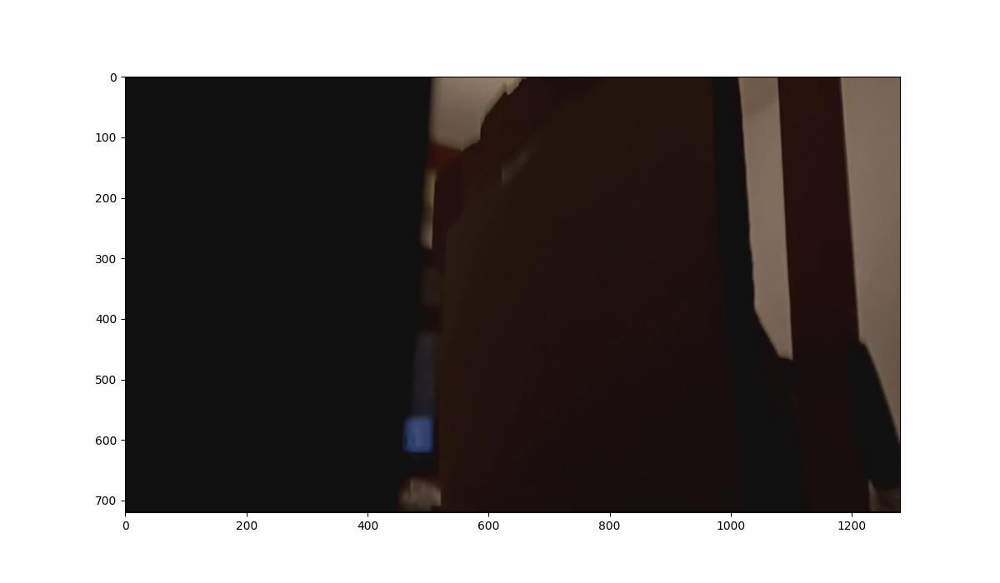

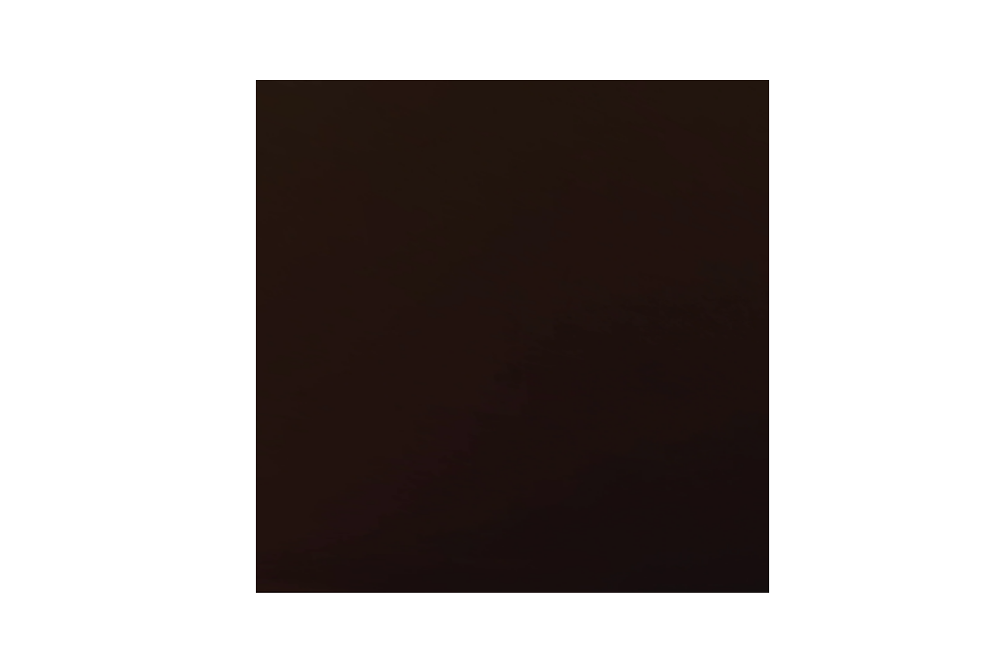

array([29.91686   , 19.65500667, 16.8353    ])

In [90]:
%matplotlib widget

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(rgb_array)
ax.axis("on")

info = ax.text(
    0.02, 0.98, "",
    transform=ax.transAxes,
    color="white",
    verticalalignment="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

def onclick(event):
    if event.inaxes != ax or event.xdata is None or event.ydata is None:
        return

    x = int(round(event.xdata))
    y = int(round(event.ydata))

    if 0 <= y < u_cut.shape[0] and 0 <= x < u_cut.shape[1]:
        rgb = u_cut[y, x]
        info.set_text(f"x={x}, y={y}, RGB={rgb}")
        fig.canvas.draw_idle()

fig.canvas.mpl_connect("button_press_event", onclick)
plt.show()

u_cut = rgb_array[200:600,400:775,:]
u_cut_feature1 = u_cut[0:200,:]
u_cut_feature2 = u_cut[200:400,:]
u_cut_feature3 = u_cut[:,100:200]


u_rect = rectify_image(
    rgb_array,
    [593,243],
    [828,65],
    [550,719],
    [850,716],
    wOut=400,
    hOut=400
)

plt.figure(figsize=(12, 8))
plt.imshow(u_rect)
plt.axis("off")
plt.show()

np.mean(u_cut,axis=(0,1))

In [91]:
def reconstruct_linescan(frame_colors, frames_per_line=150, offset=0):

    n_frames = len(frame_colors)

    # Bildbreite
    width = int(round(frames_per_line))

    # Anzahl Linien
    n_lines = int(np.ceil(n_frames / frames_per_line))

    # Ergebnisbild
    image = np.zeros((n_lines, width, 3), dtype=np.uint8)

    for line in range(n_lines):

        # Frame-Bereich dieser Linie
        start = int(round(line * frames_per_line + offset))
        end = int(round((line + 1) * frames_per_line + offset))

        end = min(end, n_frames)

        line_data = frame_colors[start:end]

        if len(line_data) == 0:
            continue

        # Scanrichtung: jede zweite Linie umdrehen
        if line % 2 == 1:
            line_data = line_data[::-1]

        # Auf konstante Bildbreite interpolieren
        old_x = np.linspace(0, 1, len(line_data))
        new_x = np.linspace(0, 1, width)

        for channel in range(3):
            image[line, :, channel] = np.interp(
                new_x,
                old_x,
                line_data[:, channel]
            )

    return image


In [95]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

frames_per_line = 152.90
offset = 76.90

def update_linescan(frames_per_line_input, offset_input):
    global frames_per_line, offset
    frames_per_line = frames_per_line_input
    offset = offset_input
    
    linescan_image = reconstruct_linescan(
        frame_features,
        frames_per_line=frames_per_line,
        offset=offset
    )

    plt.figure(figsize=(16, 8))
    plt.imshow(linescan_image)
    plt.axis("off")
    plt.show()

slider_frames = widgets.FloatSlider(
    value=frames_per_line,
    min=10,
    max=1000,
    step=0.001,
    description="Frames/Line:",
    continuous_update=False,
    layout=widgets.Layout(width="600px")
)

slider_offset = widgets.FloatSlider(
    value=offset,
    min=0,
    max=1000,
    step=0.1,
    description="Offset:",
    continuous_update=False,
    layout=widgets.Layout(width="600px")
)

widgets.interactive(
    update_linescan,
    frames_per_line_input=slider_frames,
    offset_input=slider_offset
)

interactive(children=(FloatSlider(value=152.9, continuous_update=False, description='Frames/Line:', layout=Lay…

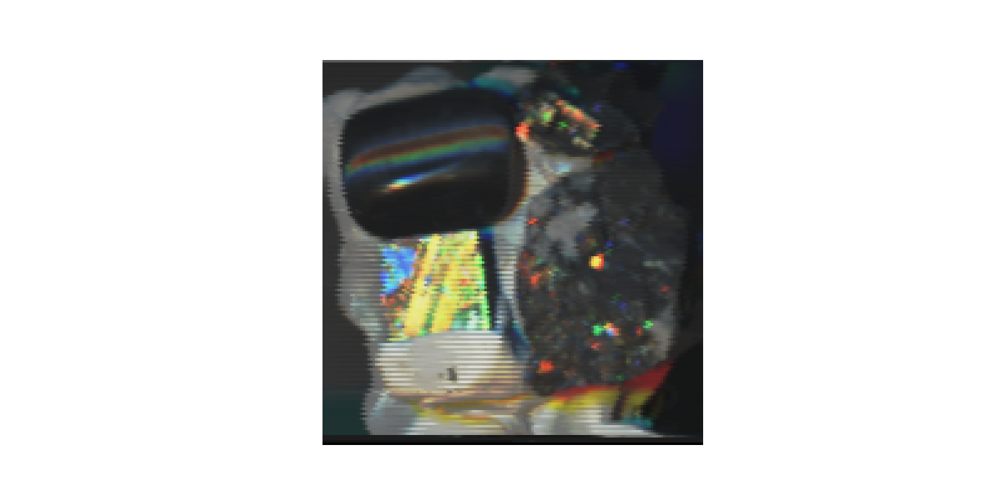

152.9

In [100]:
linescan_image = reconstruct_linescan(
    frame_angles[:,[253,213,173]],
    frames_per_line=frames_per_line,
    offset=offset
)

plt.figure(figsize=(16, 8))
plt.imshow(linescan_image)
plt.axis("off")
plt.show()

frames_per_line

In [98]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

n_anim = frame_angles.shape[1]  # 400 Kacheln

fig, ax = plt.subplots(figsize=(12, 8))

img = reconstruct_linescan(
    np.stack([
        frame_angles[:, 0],
        frame_angles[:, 0],
        frame_angles[:, 0]
    ], axis=1),
    frames_per_line=frames_per_line,
    offset=offset
)

im = ax.imshow(img, cmap="viridis")
ax.axis("off")

def update(i):
    yi = int(i/20)
    xi = i%20
    if yi%2 == 1:
        xi = 19 - xi
    
    x = yi
    y = xi
    
    #x = xi
    #y = yi
    
    j = y*20 + x
    
    
    linescan_image = reconstruct_linescan(
        np.stack([
            frame_angles[:, j],
            frame_angles[:, j],
            frame_angles[:, j]
        ], axis=1),
        frames_per_line=frames_per_line,
        offset=offset
    )

    im.set_data(linescan_image)
    ax.set_title(f"Kachel {x}|{y} {j}")

    return [im]

ani = animation.FuncAnimation(
    fig,
    update,
    frames=n_anim,
    interval=33,
    blit=False
)

plt.close(fig)

display(HTML(ani.to_jshtml()))

from IPython.display import FileLink, display

display(FileLink("linescan_animation.mp4"))

C:\Users\User\Documents\studium\Bildverarbeitung_Computervision\Laserflex\tools\video_extract\linescan_animation.mp4

In [61]:

output_path = os.path.abspath("linescan_animation.mp4")

ani.save(
    output_path,
    writer="ffmpeg",
    fps=30,
    dpi=75
)

print("Gespeichert unter:", output_path)
print("Datei existiert:", os.path.exists(output_path))

Gespeichert unter: C:\Users\User\Documents\studium\Bildverarbeitung_Computervision\Laserflex\tools\video_extract\linescan_animation.mp4
Datei existiert: True
